# Epistemic sources: which uncertainty source ranks the error best (paper format)

Paper version of `three_channels_analysis/canal_2/canal2_uncertainty_vs_error_epistemic.ipynb` (cells 2, 4, 6), which is where the cascade, the inventory and the guards live. This notebook draws the figure.
Two things to keep in mind when reading it:

- **The arms are not all the same weights.** MC-dropout and Laplace are replayed on `pr_classic1`, the own head is read on `pr_classic3`, the deep ensemble is `de_6`. The first two are launches of the same sweep (measured gap ~0.002); the ensemble is a separate training, so comparing it mixes estimator and checkpoint.
- **Color encodes the SOURCE here, never the model.** The models are the rows, named on the y axis. This palette must not be carried into a figure where a model is color-encoded.
- `_raw` heads stay out of the figure (their error lives on another axis); they remain in the printed tables.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))
from src.evaluation.benchmark_summary import donor_lopo_stats

# =============================== SETTINGS ====================================
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"

# The 7 heads that carry both post-hoc estimators under pr_classic1 AND the de_6 members.
# The LEAF carries the lambda_ segment for the Gaussian family in the single-model tree, and none
# at all for the count family -- exactly as the results tree stores it.
MODEL_LEAF = {
    "heteroscedastic":                      "heteroscedastic/lambda_0.0",
    "homoscedastic":                        "homoscedastic/lambda_0.0",
    "spot_homoscedastic":                   "spot_homoscedastic/lambda_0.0",
    "poisson_cp":                           "poisson_cp",
    "negativebinomial_hetero_noanchor_cp":  "negativebinomial_hetero_noanchor_cp",
    "poisson_raw":                          "poisson_raw",
    "negativebinomial_hetero_noanchor_raw": "negativebinomial_hetero_noanchor_raw",
}
MODELS     = list(MODEL_LEAF)
RAW_MODELS = ["poisson_raw", "negativebinomial_hetero_noanchor_raw"]

# ONE channel at a time. Mixing total and epistemic in one figure makes it unreadable AND
# compares two different questions: `total` is the like-for-like comparison against the head's
# own, which already conflates the two components, while `epistemic` alone asks which of the
# two does the ranking. Re-run the notebook with the other value for the other question.
CHANNEL = "epistemic"          # "total" | "epistemic" | "aleatoric"
_SUB_MC  = {"total": "canal2_total_mc", "epistemic": "canal2_epistemic",
            "aleatoric": "canal2_aleatoric_mc"}
SOURCES = [
    dict(key="own", label="pr_classic3", run_id="pr_classic3", ens=False,
         sub="canal2_uncertainty",             name="own head"),
    dict(key="mc",  label="pr_classic1", run_id="pr_classic1", ens=False,
         sub=_SUB_MC[CHANNEL],                 name=f"MC-dropout ({CHANNEL})"),
    dict(key="lap", label="pr_classic1", run_id="pr_classic1", ens=False,
         sub=f"canal2_laplace_{CHANNEL}",      name=f"Laplace ({CHANNEL})"),
    dict(key="de",  label="de_6",        run_id="de_6",        ens=True,
         sub=f"canal2_uncertainty/{CHANNEL}",  name=f"Deep Ensemble ({CHANNEL})"),
]
# The cases DRAWN, one PDF each in a single execution.
# lin_all is DRAWN here but does not read like the other two. At y = 0 the absolute
# error IS |mu|, so the NAIVE value tends to the uncertainty-mean coupling BY
# CONSTRUCTION, and the partial is ill-conditioned there (r_Dm -> 1). These panels
# DEMONSTRATE the confound; they do not measure it. The measurement is lin_pos.
PLOT_CASES = ["lin_all", "lin_pos", "log_pos"]   # the order is the display order
FIGDIR     = PROJ / "results" / "_analysis" / "figures_paper"
# =============================================================================

N_PLUS_MIN = 60
CONVENTION = "v3_native_scale"
CASES = PLOT_CASES
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
AXES = ["gene", "spot"]
CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
    "poisson_raw":                          "Poisson (raw counts)",
    "negativebinomial_hetero_noanchor_raw": "Negative binomial (raw counts)",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}
# One color per SOURCE here (not per model): the source is what is being compared. The three
# post-hoc estimators reuse the canonical estimator palette. The head's own
# keeps a neutral gray, it is the reference and not an estimator.
# KNOWN COLLISION: these are the saturated twins of the tab10 blue / green / red that designate
# gene-homoscedastic, spot-homoscedastic and Poisson elsewhere. The palette holds only in a
# figure where NO model is encoded by a color -- here the models are the ROWS, named on the
# y axis. Do not carry it elsewhere.
SOURCE_COLORS = {"own": "#444444", "mc": "b", "lap": "g", "de": "r"}

DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}


def canal2_dir(src, ds, model):
    """The canal2 directory of one (source, cohort, head). Three path families, not one:
    the single-model tree carries a lambda_ segment for the Gaussians, the ensemble tree goes
    through .../ensemble/ and carries none."""
    base = (PROJ / "results" / ds / src["run_id"]
            / f"_{ds}_hvg_top3000" / RADIUS)
    leaf = model if src["ens"] else MODEL_LEAF[model]
    return (base / leaf / "ensemble" / src["sub"]) if src["ens"] else (base / leaf / src["sub"])


# -- inventory ----------------------------------------------------------------------------
SUMM, PAIR, SPOT, missing, stale, na = {}, {}, {}, [], [], []
for src in SOURCES:
    for ds in DATASETS:
        for m in MODELS:
            d = canal2_dir(src, ds, m)
            if not (d / "summary.json").is_file():
                missing.append((src["key"], ds, m))
                continue
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable"):
                na.append((src["key"], ds, m))
                continue
            if s.get("canal2_convention") != CONVENTION:
                stale.append((src["key"], ds, m, s.get("canal2_convention")))
                continue
            k = (src["key"], ds, m)
            SUMM[k] = s
            if (d / "pair_partial.parquet").is_file():
                PAIR[k] = pd.read_parquet(d / "pair_partial.parquet")
            if (d / "spot_partial.parquet").is_file():
                SPOT[k] = pd.read_parquet(d / "spot_partial.parquet")

print("=" * 110)
print("INVENTORY - how many (cohort, head) per source, out of a maximum of "
      f"{len(DATASETS) * len(MODELS)}")
print("=" * 110)
for src in SOURCES:
    got = sum(1 for (k, _, _) in SUMM if k == src["key"])
    print(f"  {src['name']:<28s} {src['label']:<13s} {src['sub']:<34s} {got:>2d} run(s)")

# The sources do not necessarily come from the same training. Say it HERE, from the data.
_arms = sorted({s['label'] for s in SOURCES})
if len(_arms) > 1:
    print(f"\n(!) The sources come from {len(_arms)} training arms: {_arms}")
    for a in _arms:
        print(f"      {a:<13s} : {[s['key'] for s in SOURCES if s['label'] == a]}")
    print("    pr_classic1 / pr_classic3 are two LAUNCHES of the same sweep, not the same weights.")
    print("    Measured gap ~0.002. Negligible against a between-source gap of order 0.05;")
    print("    not against a gap of 0.005. de_6 is a separate training.")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r} - DROPPED.")
    for k, ds, m, c in stale[:12]:
        print(f"    {k:<9s} {ds:<12s} {m:<40s} convention read: {c!r}")
    if len(stale) > 12:
        print(f"    ... and {len(stale) - 12} more")
if na:
    print(f"\n{len(na)} run(s) 'not_applicable' (canal 2 does not apply to them): {na[:6]}")
if missing:
    print(f"\n(!) {len(missing)} (source, cohort, head) WITHOUT summary.json:")
    for k in sorted({x[0] for x in missing}):
        w = [f"{ds}/{m}" for (kk, ds, m) in missing if kk == k]
        print(f"    {k:<9s} {len(w):>2d} missing: {w[:4]}{' ...' if len(w) > 4 else ''}")

INVENTORY - how many (cohort, head) per source, out of a maximum of 21
  own head                     pr_classic3   canal2_uncertainty                 21 run(s)
  MC-dropout (epistemic)       pr_classic1   canal2_epistemic                   21 run(s)
  Laplace (epistemic)          pr_classic1   canal2_laplace_epistemic           21 run(s)
  Deep Ensemble (epistemic)    de_6          canal2_uncertainty/epistemic       21 run(s)

(!) The sources come from 3 training arms: ['de_6', 'pr_classic1', 'pr_classic3']
      de_6          : ['de']
      pr_classic1   : ['mc', 'lap']
      pr_classic3   : ['own']
    pr_classic1 / pr_classic3 are two LAUNCHES of the same sweep, not the same weights.
    Measured gap ~0.002. Negligible against a between-source gap of order 0.05;
    not against a gap of 0.005. de_6 is a separate training.


## 1. The donor cascade and the printed twin

The mono-source cascade, unchanged: per group, then gene weighted by n, then donor, then K points and a Student-t interval on the gene axis; a simple mean over the donor's spots on the spot axis.

Read the **controlled** column, never the naive one. The naive value mostly measures the uncertainty-to-mean coupling, which differs from source to source, so it would rank the sources on that coupling rather than on their informativeness. `*` = the donor interval excludes zero.

In [2]:
def donor_points(frame, ds, axis, case, stat):
    """{donor: value} + the number of groups kept. Cascade identical to the script's;
    only the donor boundary is added."""
    col, ncol = f"{stat}_{case}", N_COL[case]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return {}, 0
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return {}, 0
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    if axis == "spot":                       # one spot = one slide = one donor
        return d.groupby(donor.to_numpy())[col].mean().to_dict(), int(len(d))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]
    return g.groupby("donor")["v"].mean().to_dict(), int(len(d))


rows = []
for (key, ds, m) in SUMM:
    for case in CASES:
        for axis in AXES:
            frame = (PAIR if axis == "gene" else SPOT).get((key, ds, m))
            rec = dict(source=key, dataset=ds, model=m, case=case, axis=axis)
            for stat, tag in (("r_uD", "naive"), ("r_partial", "partial")):
                pts, n = donor_points(frame, ds, axis, case, stat)
                if not pts:
                    continue
                st = donor_lopo_stats(pts)
                rec.update({tag: st["mean"], f"{tag}_lo": st["ci95_mean"][0],
                            f"{tag}_hi": st["ci95_mean"][1], "K": st["K"], f"{tag}_n": n})
            rows.append(rec)
RES = pd.DataFrame(rows)


def get(key, ds, m, case, axis):
    r = RES[(RES["source"] == key) & (RES["dataset"] == ds) & (RES["model"] == m)
            & (RES["case"] == case) & (RES["axis"] == axis)] if not RES.empty else RES
    return None if r.empty else r.iloc[0]


def cell(r, tag, width=26):
    if r is None:
        return f"{'absent':>{width}s}"
    v = r.get(tag, np.nan)
    if not np.isfinite(v):
        return f"{'mute':>{width}s}"
    lo, hi = r.get(f"{tag}_lo", np.nan), r.get(f"{tag}_hi", np.nan)
    if not np.isfinite(lo):
        return f"{v:>+{width}.4f}"
    star = "*" if (lo > 0 or hi < 0) else " "
    return f"{v:+.4f} [{lo:+.4f},{hi:+.4f}]{star}".rjust(width)


for case in CASES:
    for axis in AXES:
        print("\n" + "#" * 126)
        print(f"# AXIS {axis.upper()} - case {case} ({CASE_FIG[case]})")
        print("#   'mute' = partial undefined by construction.  'absent' = precompute not run.")
        print("#" * 126)
        for ds in DATASETS:
            print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
            print(f"  {'head':<40s} " + " ".join(f"{s['name'][:24]:>26s}" for s in SOURCES))
            for m in MODELS:
                cells = " ".join(cell(get(s["key"], ds, m, case, axis), "partial")
                                 for s in SOURCES)
                if all("absent" in c for c in cells.split()):
                    continue
                print(f"  {MODEL_LABELS.get(m, m):<40s} {cells}")


##############################################################################################################################
# AXIS GENE - case lin_all (|y - mu|, all (spot, gene) entries, zeros included)
#   'mute' = partial undefined by construction.  'absent' = precompute not run.
##############################################################################################################################

--- Tumor Profiler ---
  head                                                       own head     MC-dropout (epistemic)        Laplace (epistemic)   Deep Ensemble (epistemic
  Gaussian heteroscedastic                 +0.0578 [+0.0395,+0.0761]* +0.0287 [+0.0103,+0.0471]* +0.0388 [+0.0191,+0.0585]* +0.0208 [+0.0121,+0.0295]*
  Gaussian gene-homoscedastic                                    mute +0.0194 [+0.0107,+0.0281]* +0.0386 [+0.0157,+0.0615]* +0.0252 [+0.0172,+0.0331]*
  Gaussian spot-homoscedastic              +0.0579 [+0.0430,+0.0728]* +0.0313 [+0.0175,+0.0452]* +0.0310 [-0

## 2. The paper figure — 2 axes x 3 cohorts, one PDF per error case

One panel per cohort, one row per head, one marker per source with its Student-t interval over donors. A head that leaves nothing at its position is mute or absent, which is information rather than a data hole.

The `_raw` heads are excluded from the figure: their error is measured against a target carrying the spot's library size, a different error axis. They stay in the printed tables above.

Knobs: `COL_W` (width per cohort, the cheap axis), `ROW_H`, `LEGEND_FS`, `LEGEND_GUTTER`, `BOTTOM_PAD`.

[lin_all] legend strip = 0.175 of the width


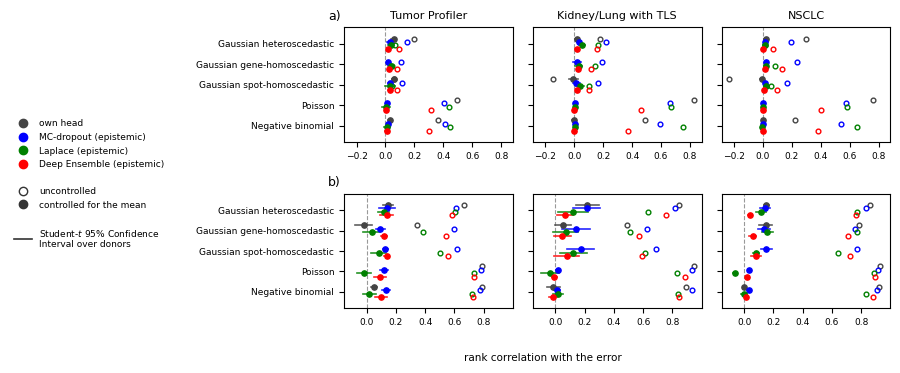

## FIGURE  fig_canal2_sources_paper_epistemic_lin_all.pdf
## TITLE   Which source of predictive uncertainty ranks the prediction error best, on both groupings
## CAPTION Error definition: |y - mu|, all (spot, gene) entries, zeros included.
## CAPTION One row per predictive head within a panel, one marker per uncertainty source (color).
## CAPTION Hollow: no control. Filled: the partial correlation between that source and the absolute
## CAPTION error within a group, the predicted mean being partialled out as a rank covariate. Bar:
## CAPTION Student-t 95% interval over the held-out donors, on the controlled value only.
## CAPTION a) one group per gene and slide, ranking the error across the spots of that gene.
## CAPTION b) one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION A source missing on a row is MUTE there by construction, not absent from the data: its
## CAPTION uncertainty carries no degree of freedom independent of the mean.
## CAPTION O

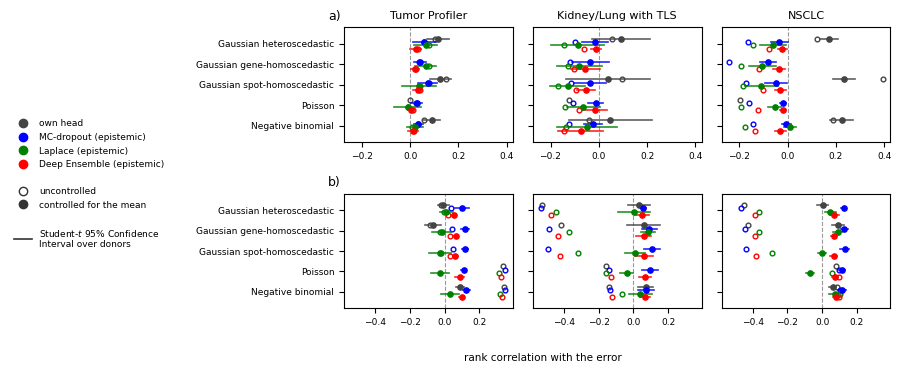

## FIGURE  fig_canal2_sources_paper_epistemic_lin_pos.pdf
## TITLE   Which source of predictive uncertainty ranks the prediction error best, on both groupings
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One row per predictive head within a panel, one marker per uncertainty source (color).
## CAPTION Hollow: no control. Filled: the partial correlation between that source and the absolute
## CAPTION error within a group, the predicted mean being partialled out as a rank covariate. Bar:
## CAPTION Student-t 95% interval over the held-out donors, on the controlled value only.
## CAPTION a) one group per gene and slide, ranking the error across the spots of that gene.
## CAPTION b) one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION A source missing on a row is MUTE there by construction, not absent from the data: its
## CAPTION uncertainty carries no degree of freedom independent of the mean.
## CAPTION Own head, MC

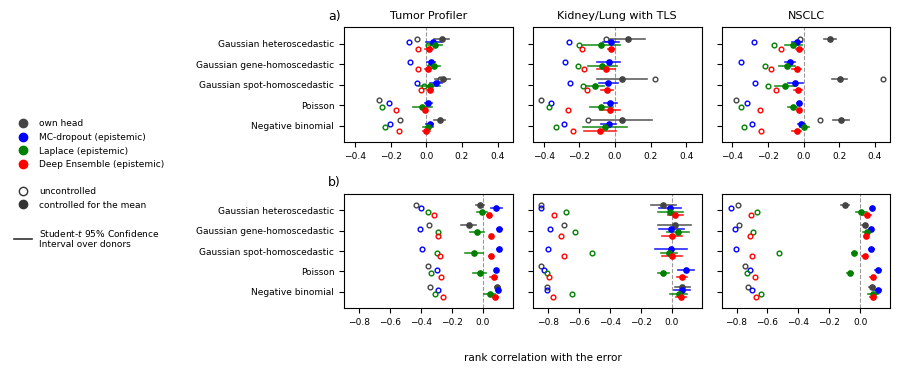

## FIGURE  fig_canal2_sources_paper_epistemic_log_pos.pdf
## TITLE   Which source of predictive uncertainty ranks the prediction error best, on both groupings
## CAPTION Error definition: |log y - log mu|, detected entries only (y > 0).
## CAPTION One row per predictive head within a panel, one marker per uncertainty source (color).
## CAPTION Hollow: no control. Filled: the partial correlation between that source and the absolute
## CAPTION error within a group, the predicted mean being partialled out as a rank covariate. Bar:
## CAPTION Student-t 95% interval over the held-out donors, on the controlled value only.
## CAPTION a) one group per gene and slide, ranking the error across the spots of that gene.
## CAPTION b) one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION A source missing on a row is MUTE there by construction, not absent from the data: its
## CAPTION uncertainty carries no degree of freedom independent of the mean.
## CAPTION Own 

In [3]:
from matplotlib.lines import Line2D

FIGDIR.mkdir(parents=True, exist_ok=True)


def fig_show(fig, stem, title, caption):
    """Save .pdf + .png, show, then PRINT the title and caption."""
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


AXIS_GROUPING = {
    "gene": "one group per gene and slide, ranking the error across the spots of that gene",
    "spot": "one group per slide and spot, ranking the error across the genes of that spot",
}
PLOT_MODELS = [m for m in MODELS if m not in RAW_MODELS]

# WIDTH is the cheap axis: LaTeX places the figure at FIXED width, so widening reduces the
# fraction taken by the legend strip AND the printed height. Here the left carries TWO things,
# the legend and the head names on the y axis, hence a more generous width per cohort.
COL_W         = 3.0
ROW_H         = 1.9     # height per row
LEGEND_FS     = 6.5
LEGEND_GUTTER = 0.02
BOTTOM_PAD    = 0.085   # strip reserved for the SHARED axis label

for case in PLOT_CASES:
    drawn = []
    fig, axes = plt.subplots(len(AXES), len(DATASETS),
                             figsize=(COL_W * len(DATASETS), ROW_H * len(AXES)),
                             sharex="row", squeeze=False)
    for i, axis in enumerate(AXES):
        for j, ds in enumerate(DATASETS):
            ax = axes[i, j]
            for y0, m in enumerate(PLOT_MODELS):
                for k, s in enumerate(SOURCES):
                    r = get(s["key"], ds, m, case, axis)
                    if r is None:
                        continue
                    # vertical offset per source, so the intervals do not overlap
                    y = y0 + (k - (len(SOURCES) - 1) / 2) * 0.17
                    c = SOURCE_COLORS.get(s["key"], "0.5")
                    nv, pv = r.get("naive", np.nan), r.get("partial", np.nan)
                    # HOLLOW = uncontrolled, FILLED = controlled, interval on the control only.
                    # A source with no filled marker is MUTE on this axis by construction, and
                    # its hollow marker says where it started from.
                    if np.isfinite(nv):
                        ax.plot([nv], [y], "o", ms=3.4, mfc="none", mec=c, mew=1.0, zorder=3)
                    if not np.isfinite(pv):
                        # MUTE on this axis. The HOLLOW marker was drawn anyway, so
                        # it must appear in the printed twin: leaving without recording
                        # would leave a drawn marker outside the numbers.
                        drawn.append(dict(case=case, axis=axis, dataset=ds, model=m,
                                          source=s["key"], naive=nv, partial=np.nan,
                                          lo=np.nan, hi=np.nan))
                        continue
                    lo, hi = r.get("partial_lo", np.nan), r.get("partial_hi", np.nan)
                    if np.isfinite(lo):
                        ax.plot([lo, hi], [y, y], color=c, lw=1.2, alpha=0.85, zorder=3)
                    ax.plot([pv], [y], "o", color=c, ms=3.8, zorder=4)
                    drawn.append(dict(case=case, axis=axis, dataset=ds, model=m,
                                      source=s["key"], naive=nv, partial=pv, lo=lo, hi=hi))
            ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
            ax.set_yticks(range(len(PLOT_MODELS)))
            # The head names are written ONLY on column 0: the color encodes the source,
            # so the head must be named somewhere, and the y axis is the only place where it
            # does not cost space in every column.
            ax.set_yticklabels([MODEL_LABELS.get(m, m) for m in PLOT_MODELS] if j == 0 else [],
                               fontsize=6.5)
            ax.invert_yaxis()
            ax.margins(y=0.12)
            ax.tick_params(axis="x", labelsize=6.5)
            if j == 0:
                ax.text(-0.02, 1.04, f"{'ab'[i]})", transform=ax.transAxes,
                        ha="right", va="bottom", fontsize=9)
            if i == 0:
                ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
            # NO per-panel set_xlabel: three copies of the same text overlap.

    src_handles = [Line2D([], [], marker="o", ls="", color=SOURCE_COLORS.get(s["key"], "0.5"),
                          label=s["name"]) for s in SOURCES]
    spacer, spacer2 = (Line2D([], [], ls="", marker="", label="") for _ in range(2))
    cond_handles = [Line2D([], [], marker="o", ls="", mfc="none", mec="#333333", mew=1.0,
                           label="uncontrolled"),
                    Line2D([], [], marker="o", ls="", color="#333333",
                           label="controlled for the mean")]
    bar_handle = [Line2D([], [], color="#333333", lw=1.2, marker="",
                         label="Student-$t$ 95% Confidence \nInterval over donors")]
    leg = fig.legend(handles=src_handles + [spacer] + cond_handles + [spacer2] + bar_handle,
                     loc="center left", bbox_to_anchor=(0.0, 0.5),
                     ncol=1, frameon=False, fontsize=LEGEND_FS)
    fig.canvas.draw()
    legend_w = leg.get_window_extent().width / fig.bbox.width
    left = legend_w + LEGEND_GUTTER
    fig.tight_layout(rect=(left, BOTTOM_PAD, 1, 1))
    fig.text((left + 1) / 2, BOTTOM_PAD / 2, "rank correlation with the error",
             ha="center", va="center", fontsize=7.5)
    print(f"[{case}] legend strip = {legend_w:.3f} of the width")

    caption = [
        f"Error definition: {CASE_FIG[case]}.",
        "One row per predictive head within a panel, one marker per uncertainty source (color).",
        "Hollow: no control. Filled: the partial correlation between that source and the absolute",
        "error within a group, the predicted mean being partialled out as a rank covariate. Bar:",
        "Student-t 95% interval over the held-out donors, on the controlled value only.",
    ]
    for q, axis in enumerate(AXES):
        caption.append(f"{'ab'[q]}) {AXIS_GROUPING[axis]}.")
    caption += [
        "A source missing on a row is MUTE there by construction, not absent from the data: its",
        "uncertainty carries no degree of freedom independent of the mean.",
        "Own head, MC-dropout and Laplace read one training arm, the deep ensemble another, so the",
        "ensemble comparison mixes estimator and checkpoint.",
        "Depth-blind heads are excluded: their error lives on a different axis.",
        "Rows are not drawn on a shared horizontal scale: the two groupings are duals.",
    ]
    fig_show(fig, FIGDIR / f"fig_canal2_sources_paper_{CHANNEL}_{case}",
             f"Which source of predictive uncertainty ranks the prediction error best, on both "
             f"groupings",
             caption)

    D = pd.DataFrame(drawn)
    print("\n" + "=" * 112)
    print(f"THE PRINTED TWIN - case {case}, exactly the plotted values")
    print("=" * 112)
    for axis in AXES:
        for ds in DATASETS:
            sub = D[(D["axis"] == axis) & (D["dataset"] == ds)] if not D.empty else D
            if sub.empty:
                continue
            print(f"\n[axis {axis} | {DATASET_LABELS.get(ds, ds)}]")
            print(f"    {'head':<40s} {'source':<8s} {'naive':>9s} {'control':>9s}")
            for _, r in sub.iterrows():
                ci = f"[{r['lo']:+.4f}, {r['hi']:+.4f}]" if np.isfinite(r["lo"]) else "n/a"
                nv = f"{r['naive']:+.4f}" if np.isfinite(r["naive"]) else "     n/a"
                pv = f"{r['partial']:+.4f}" if np.isfinite(r["partial"]) else "    mute"
                print(f"    {MODEL_LABELS.get(r['model'], r['model']):<40s} "
                      f"{r['source']:<8s} {nv:>9s} {pv:>9s} {ci:>22s}")